# Horizon Forecaster — daily example

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Lifesight-Software-Pvt-Ltd/horizon/blob/main/examples/daily_website_traffic.ipynb)

A complete daily run: evaluate five forecasting models on one series, combine them,
forecast forward, and export the results.

**What this notebook shows**

- the three-way train / validation / test split, and why the two MAPEs it reports are not interchangeable
- several combination rules built side by side, and how to tell whether any of them beat the best single model
- supplying future values for the drivers you *do* know, while the library generates the ones you do not
- the calibrated 95% band every model and combination carries, and how to check it
- the chart and CSV outputs

There is a weekly counterpart in this folder; the API is identical, only the frequency defaults differ.

---

### Dataset

**Personal Ecommerce Website Ad cost & viewer count**, by Kaggle user `michealknight`, licensed **Apache 2.0**.
Source: https://www.kaggle.com/datasets/michealknight/personal-ecommerce-website-ad-cost-and-viewer-count

The CSV in `examples/data/` is the file exactly as downloaded — no columns removed, no values changed.
Every bit of preparation happens in this notebook, in the open, so you can disagree with any of it.
1096 daily rows, 2022-01-01 to 2024-12-31.

**This is simulated data**, as the dataset's own Kaggle subtitle says ("Simulated Daily Web Analytics"). That suits this notebook: its job is to show how the library works end to end on an external dataset, not to make claims about any real website's traffic.

## Before you run

**This notebook fits real models.** The saved outputs come from the full five-model run
(`FAST = False` in §2), which takes considerably longer on a free Colab CPU — expect about half an hour, plus the install,
because Bayesian PyMC draws a full MCMC sample per grid candidate. Set `FAST = True` for a three-model
run that takes a few minutes. Prophet and PyMC also compile on first use.

**On Colab specifically:** the default runtime is Python 3.13, and `neuralprophet` pins `numpy<2`,
which publishes no 3.13 wheel — so pip compiles numpy from source and the install takes several extra minutes.
To skip that, set **Runtime → Change runtime type → Runtime version → 2026.07** (Python 3.12) before running.
See [`docs/installation.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/installation.md) for the full explanation.

In [1]:
# Installing from the repository. Once the package is on PyPI this becomes:
#     %pip install -q horizon_forecaster
%pip install -q "horizon_forecaster @ git+https://github.com/Lifesight-Software-Pvt-Ltd/horizon.git"

Colab's default runtime has `numpy 2.x` already loaded before you run anything. Horizon pins
`numpy==1.26.4`, because NeuralProphet requires `numpy<2`; the install above downgrades it, but Python
cannot swap a C-extension library like numpy inside a running session. Without a restart, the next cell
fails with `ValueError: numpy.dtype size changed, may indicate binary incompatibility`.
The install may also end with a red `ERROR: pip's dependency resolver ...` list: packages Colab
preinstalls (`jax`, `opencv`, `shap` and others) want `numpy>=2` or another `pandas` version. This
notebook does not import them, and the run is unaffected.

**Run the cell below.** On Colab, when the loaded numpy differs from the installed one, it restarts the
session: Colab disconnects and reconnects in a few seconds (expected, not an error). It does nothing
otherwise — after the restart, or when running locally — so *Run all* is safe to repeat.

**After it reconnects, do not re-run the install cell.** Continue from the next cell: installed packages
persist across a restart within the same session.

In [ ]:
# Restart once on Colab if the numpy in memory is not the one just installed.
# Colab notices the stopped process and starts a fresh one. No-op otherwise,
# including after the restart and outside Colab.
import importlib.metadata
import os
import sys

loaded = sys.modules.get('numpy')
if 'google.colab' in sys.modules and loaded is not None \
        and loaded.__version__ != importlib.metadata.version('numpy'):
    os.kill(os.getpid(), 9)

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd

from horizon_forecaster import BAND_LEVEL, HorizonForecaster, __version__
from horizon_forecaster.exporters import band_coverage, export_forecast
from horizon_forecaster.plotting import (
    plot_evaluation,
    plot_evaluation_per_model,
    plot_forecast,
    plot_forecast_per_model,
    plot_model_comparison,
)

print('horizon_forecaster', __version__, f'| bands at {BAND_LEVEL:.0%}')

# Warnings are part of the library's output -- it warns about auto-generated
# drivers, over-long horizons, outputs without a 95% band and implausible
# forecasts. Keep them visible.
warnings.simplefilter('always', UserWarning)

horizon_forecaster 1.0.0 | bands at 95%


## 1. The data

Loaded straight from the repository, so this runs in Colab with nothing to download by hand.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/Lifesight-Software-Pvt-Ltd/horizon/main/examples/data/final_website_stats.csv"

raw = pd.read_csv(DATA_URL)
print(raw.shape)
raw.head()

(1096, 7)


,Unnamed: 0,timestamp,page_views,ad_spend,is_weekend,day_of_week,is_holiday
0,0,2022-01-01,1165.962767,194.901425,True,Saturday,True
1,1,2022-01-02,1191.485835,175.852071,True,Sunday,False
2,2,2022-01-03,1266.928269,269.430656,False,Monday,False
3,3,2022-01-04,1364.193858,295.690896,False,Tuesday,False
4,4,2022-01-05,1013.282520,242.975399,False,Wednesday,False


### Preparing it

Four changes, and the reason for each:

| Change | Why |
|---|---|
| drop the unnamed first column | a pandas index saved into the CSV, not data |
| drop `day_of_week` | a string, which the library will not accept; it is also redundant — `is_weekend` carries the signal, and Prophet and NeuralProphet model weekly seasonality natively |
| `is_weekend`, `is_holiday` to `int` | booleans are not numeric for our purposes; 0/1 also lets the library auto-detect them as event flags |
| rename `timestamp` to `date` | cosmetic |

Note what is *not* here: no filling, no imputing, no dropping of rows. The library requires complete
data and raises `InvalidConfigError` on a single missing cell or missing date rather than guessing — so the check below
is worth doing before you construct anything.

In [3]:
df = (
    raw.drop(columns=['Unnamed: 0', 'day_of_week'])
       .rename(columns={'timestamp': 'date'})
       .assign(
           date=lambda d: pd.to_datetime(d['date']),
           is_weekend=lambda d: d['is_weekend'].astype(int),
           is_holiday=lambda d: d['is_holiday'].astype(int),
       )
       .sort_values('date')
       .reset_index(drop=True)
)

# The three things the library cares about before it will take the frame.
print('rows             :', len(df))
print('missing cells    :', int(df.isna().sum().sum()))
print('duplicate dates  :', int(df['date'].duplicated().sum()))
print('day gaps present :', sorted(df['date'].diff().dt.days.dropna().unique()))
df.head()

rows             : 1096
missing cells    : 0
duplicate dates  : 0
day gaps present : [1.0]


,date,page_views,ad_spend,is_weekend,is_holiday
0,2022-01-01,1165.962767,194.901425,1,1
1,2022-01-02,1191.485835,175.852071,1,0
2,2022-01-03,1266.928269,269.430656,0,0
3,2022-01-04,1364.193858,295.690896,0,0
4,2022-01-05,1013.282520,242.975399,0,0


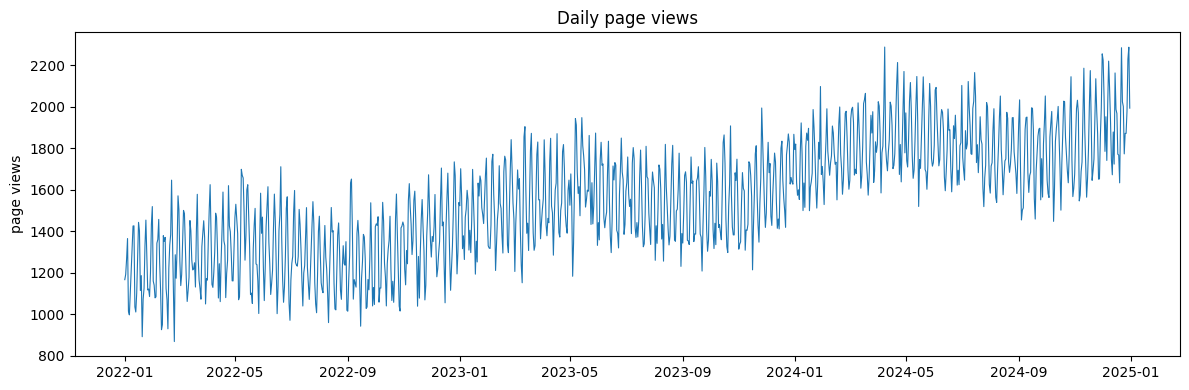

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df['date'], df['page_views'], linewidth=0.8)
ax.set_title('Daily page views')
ax.set_ylabel('page views')
fig.tight_layout()
plt.show()

Three years of daily data with a clear upward trend and visible weekly structure.
That is the kind of series this library is built for.

A note on the drivers, since an example should not oversell them: `ad_spend` correlates with
`page_views` at **-0.003** on the same day, and stays below 0.25 at every lag from 0 to 7 days (it peaks at about 0.24, four to five days later). In this dataset it carries little signal.
It is kept because it exercises the exogenous path end to end — standardisation in SARIMAX, the
regression term in Bayesian PyMC — not because it helps the forecast. `is_weekend` and `is_holiday`
are the drivers that actually matter here, and both are *known in advance*, which §5 makes use of.

## 2. Constructing the forecaster

Every argument below is optional except the first four. Most values shown are the defaults,
written out so you can see what you would otherwise be accepting; the two that are not are
`ensemble_method=None` (build all three rules, rather than only `trimmed`) and `event_columns`
(declared rather than auto-detected).

In [5]:
TARGET   = 'page_views'
DRIVERS  = ['ad_spend', 'is_weekend', 'is_holiday']

# All five models, each fully grid-searched -- this is the run the saved outputs show.
# Set FAST = True for three models in a few minutes; see the note at the top about runtime.
FAST = False
MODELS = ['prophet', 'catboost', 'sarimax'] if FAST else None   # None = every registered model

forecaster = HorizonForecaster(
    df,
    date_column='date',
    target_column=TARGET,
    frequency='daily',
    independent_columns=DRIVERS,
    validation_size=None,      # None -> 84 periods for daily. Every DECISION is scored here.
    test_size=None,            # None -> 28 periods for daily. REPORTED; only the best-model export also checks it.
    models=MODELS,
    mape_threshold=40.0,       # degenerate-fit filter on the validation score; None admits everything
    selection_metric='auto',   # 'auto' -> MAPE, or WAPE when the target is often 0 or goes negative; 'mape'/'wape' fix it
    model_params=None,         # None -> grid-search every model; see the note below
    ensemble_method=None,      # None -> build all three rules: trimmed, inverse_mape, equal
    future_exog_strategy='carry_forward',
    event_columns=['is_weekend', 'is_holiday'],   # 0/1 flags; declaring them beats auto-detection
)

print('models      :', MODELS or 'all registered')
print('ensembles   :', forecaster.ensemble_methods)

models      : all registered
ensembles   : ['trimmed', 'inverse_mape', 'equal']


**Two choices the defaults make for you.**

- **`selection_metric`** decides which validation score every decision is made on: the grid search,
  the `mape_threshold` screen, the inverse-MAPE weights and the exported best model. `'auto'` uses
  MAPE unless the target is 0 in 10% or more of its periods or goes negative, and then uses WAPE,
  with a warning; `'mape'` or `'wape'` fixes the choice from the start. `mape_threshold`
  screens whichever score is selected, despite its name, and `forecaster.selection_metric` says which one
  was used. Both scores are reported either way.
- **`model_params`** fixes a model's settings and skips its grid search, for example
  `model_params={'prophet': {'seasonality_mode': 'additive'}}`; anything not given comes from that
  model's defaults. The model is still scored on validation, so it is screened, weighted and given
  a band like every other. Settings that only shape a model's own interval (`interval_width` and
  `uncertainty_samples` for Prophet, `alpha` for SARIMAX, `ci_lower_pct` / `ci_upper_pct` for
  Bayesian PyMC) are refused with `InvalidConfigError`, since the library calibrates every band
  itself.

## 3. Evaluate

`evaluate()` splits the series chronologically into **train / validation / test**, grid-searches each
model's hyperparameters on the validation window, refits the winner on train + validation, and scores
it once on the test window — which no selection path is ever allowed to read.

That is why every result carries two MAPEs, and why they mean different things:

| field | window | meaning |
|---|---|---|
| `validation_mape` | validation | the score every decision was made on. Optimistic by construction — candidates were chosen to minimise it. |
| `mape` | test | the score reported. The honest out-of-sample number. |
| `validation_wape`, `wape` | validation, test | the same two windows as WAPE, which also counts the days whose actual is 0. When `forecaster.selection_metric` is `'wape'` (a target with many zeros, or one that goes negative), the decisions were made on `validation_wape`. |

A large gap between them means the grid found a candidate that suited the validation window
specifically rather than the series generally.

In [6]:
%%time
results = forecaster.evaluate()

/usr/local/lib/python3.13/dist-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)
ERROR:NP.plotly:Importing plotly failed. Interactive plots will not work.
ERROR:NP.plotly:Importing plotly failed. Interactive plots will not work.


CPU times: user 22min 30s, sys: 10 s, total: 22min 40s
Wall time: 22min 48s


In [7]:
summary = pd.DataFrame([
    {
        'model': name,
        'test MAPE %': round(r.mape.value, 2),
        'validation MAPE %': round(r.validation_mape.value, 2),
        'test WAPE %': round(r.wape, 2),
        'validation WAPE %': round(r.validation_wape, 2),
        'train': r.n_train,
        'validation': r.n_validation,
        'test': r.n_test,
    }
    for name, r in results.items()
]).sort_values('test MAPE %').reset_index(drop=True)

# selection_metric is 'mape' unless the target is 0 on 10% or more of days or goes
# negative; then every decision is made on WAPE instead (with a warning).
print('selection metric:', forecaster.selection_metric)
# The bar to clear: the same weekday last week (daily) or week last year (weekly).
print(f'seasonal naive: test MAPE {forecaster.naive_baseline.mape.value:.2f}%, '
      f'WAPE {forecaster.naive_baseline.wape:.2f}%')
summary

selection metric: mape
seasonal naive: test MAPE 5.62%, WAPE 5.44%


,model,test MAPE %,validation MAPE %,test WAPE %,validation WAPE %,train,validation,test
0,prophet,3.83,3.65,3.91,3.57,984,84,28
1,sarimax,4.02,3.64,4.02,3.54,984,84,28
2,bayesianpymc,4.07,3.60,4.12,3.51,984,84,28
3,neuralprophet,4.11,3.63,4.14,3.55,984,84,28
4,catboost,4.46,4.07,4.57,4.14,984,84,28


### What the grid search chose

Each model's candidates, best first, with their **validation** scores — the ones the choice was made
on. The first row is the setting that was refit on train + validation and scored on test. Shown for
Prophet, with only the settings its grid varies; every model's `grid_search_summary` works the same
way (`None` for a model given fixed `model_params`).

In [8]:
grid = pd.DataFrame(results['prophet'].grid_search_summary)
params = pd.json_normalize(grid['params'])
params = params.loc[:, params.astype(str).nunique() > 1]   # only the settings the grid varies
grid = pd.concat([params, grid[['mape', 'wape']]], axis=1)
grid.rename(columns={'mape': 'validation MAPE %', 'wape': 'validation WAPE %'}).round(2)

,seasonality_mode,yearly_seasonality,weekly_seasonality,validation MAPE %,validation WAPE %
0,additive,20,5,3.65,3.57
1,additive,10,3,3.66,3.59
2,additive,auto,auto,3.66,3.59
3,multiplicative,20,5,3.69,3.65
4,multiplicative,10,3,3.75,3.71
5,multiplicative,auto,auto,3.75,3.71


In [9]:
# Three outcomes, never conflated: a model skipped before fitting (SARIMAX on a target with
# negative values, say), one that failed to fit or predict, and one that fitted but was not
# admitted to a combination (the ensembles table below).
print('skipped       :', forecaster.skipped_models or 'none')
print('failed to fit :', dict(forecaster.evaluate_errors) or 'none')

skipped       : none
failed to fit : none


### The ensembles

All three rules were built from the same fitted models — combination is arithmetic over predictions
already in memory, so asking for every rule costs essentially nothing beyond the first.

`weights` is `None` for the trimmed rule, which has no weights at all. That is not an oversight:
an empty dict already means "no member survived", so a weightless rule has to report something else.

In [10]:
rows = []
for method, ens in forecaster.evaluate_ensemble.items():
    rows.append({
        'method': method,
        'rule applied': ens.rule_applied,
        'degraded': ens.degraded,
        'members': len(ens.members),
        'MAPE %': round(ens.mape.value, 2) if ens.mape is not None else None,
        'WAPE %': round(ens.wape, 2) if ens.wape is not None else None,
        'weights': ens.weights,
        'rejected': list(ens.rejected_models) or None,
    })

pd.DataFrame(rows)

,method,rule applied,degraded,members,MAPE %,WAPE %,weights,rejected
0,trimmed,trimmed,False,5,3.88,3.94,None,None
1,inverse_mape,inverse_mape,False,5,3.85,3.91,"{'prophet': 0.20312508045068345, 'catboost': 0...",None
2,equal,equal,False,5,3.85,3.91,"{'prophet': 0.2, 'catboost': 0.2, 'sarimax': 0...",None


**Compare those against the per-model table above before trusting any of them.**

A combined forecast is *not* guaranteed to beat the best single model. With static weights it can be
dragged off on exactly the periods where a weaker member is wrong; trimming is considerably more robust
to that, since it discards the offending member on the periods where it offends, but it is still not a
guarantee. This is a real property of combination, not a defect — which is why the library scores every
ensemble against actuals and the exporter writes both a combined and a best-single-model CSV. The best single model is the one with the lowest *validation* score among the models within `mape_threshold` on both validation and test; `model_summary` says why each model was or was not chosen.

**Inside the trimmed rule.** It has no weights: for each period it drops the highest and the lowest
model and averages the rest. `trim_shares` counts how often each model was the one dropped, so a
model trimmed on most periods is the one pulling away from the others. When fewer than three models
are admitted the rule falls back to a mean or a single model (`rule applied` above says which), and
there is nothing to trim.

In [11]:
trimmed = forecaster.evaluate_ensemble['trimmed']
trimmed.trim_shares if trimmed.trim_shares is not None else f'no trimming: {trimmed.rule_applied}'

,model,trimmed_low,trimmed_high,trimmed_total,n_periods,trimmed_fraction
0,prophet,4,1,5,28,0.178571
1,catboost,20,3,23,28,0.821429
2,sarimax,1,18,19,28,0.678571
3,neuralprophet,0,6,6,28,0.214286
4,bayesianpymc,3,0,3,28,0.107143


**Do the models make different mistakes?** A combination only gains from members that are wrong in
different ways. This is the correlation of the models' errors on the test window: two models near 1
make the same mistakes, so averaging them adds little, while a model with a low correlation to the
rest is the one that diversifies the blend. The export writes the same table to
`error_correlation.csv`.

In [12]:
forecaster.test_error_correlation.round(2)

,prophet,catboost,sarimax,neuralprophet,bayesianpymc
prophet,1.00,0.95,0.96,0.99,0.99
catboost,0.95,1.00,0.92,0.96,0.96
sarimax,0.96,0.92,1.00,0.98,0.97
neuralprophet,0.99,0.96,0.98,1.00,1.00
bayesianpymc,0.99,0.96,0.97,1.00,1.00


### The 95% bands

Every model and every combination rule carries a 95% band, `yhat_lower` / `yhat_upper`, built the
same way for all of them from that forecast's own errors on the validation window (split conformal
prediction). The models' own intervals are not used. With the default 84 days of
validation, the band's half-width is the 81st smallest of the 84 absolute validation errors,
and it stays that width for as far ahead as the validation window reaches.

How each band was calibrated is on `.band`. The coverage column is the share of the test window's
actuals that fell inside the band. With 28 test days, each day outside the band
moves it by about 4 points, so read it as a check that the band is in the right
range, not as a precise figure. `model_summary` reports the same two columns on every run.

In [13]:
actuals = next(iter(results.values())).test_predictions[['ds', 'y']]

band_rows = []
for name, r in results.items():
    pct, points = band_coverage(r.test_predictions)
    band_rows.append({'output': name, 'half-width': r.band.width, 'validation errors': r.band.n_errors,
                      'zero periods left out': r.band.n_zero_days_left_out,
                      'test coverage %': pct, 'test points': points})
for method, ens in forecaster.evaluate_ensemble.items():
    if ens.combined is None:
        continue
    pct, points = band_coverage(ens.combined, actuals)
    band_rows.append({'output': f'ensemble ({method})', 'half-width': ens.band.width,
                      'validation errors': ens.band.n_errors,
                      'zero periods left out': ens.band.n_zero_days_left_out,
                      'test coverage %': pct, 'test points': points})

pd.DataFrame(band_rows).round(1)

,output,half-width,validation errors,zero periods left out,test coverage %,test points
0,prophet,167.1,84,0,85.7,28
1,catboost,206.1,84,0,92.9,28
2,sarimax,147.5,84,0,82.1,28
3,neuralprophet,174.8,84,0,85.7,28
4,bayesianpymc,174.0,84,0,89.3,28
5,ensemble (trimmed),171.7,84,0,85.7,28
6,ensemble (inverse_mape),161.7,84,0,85.7,28
7,ensemble (equal),160.3,84,0,82.1,28


## 4. Charts

`plot_evaluation` returns **one chart per combination rule**, keyed by method — always a dict, even for
a single rule. Each chart carries the same models and actuals against a different combination, so the
rules are comparable against the truth rather than only against each other.

The shaded area is the 95% band. The overlay charts shade only the combination's band — five overlapping bands would hide the lines — and the per-model figures below shade each model's own.


charts returned: ['trimmed', 'inverse_mape', 'equal']


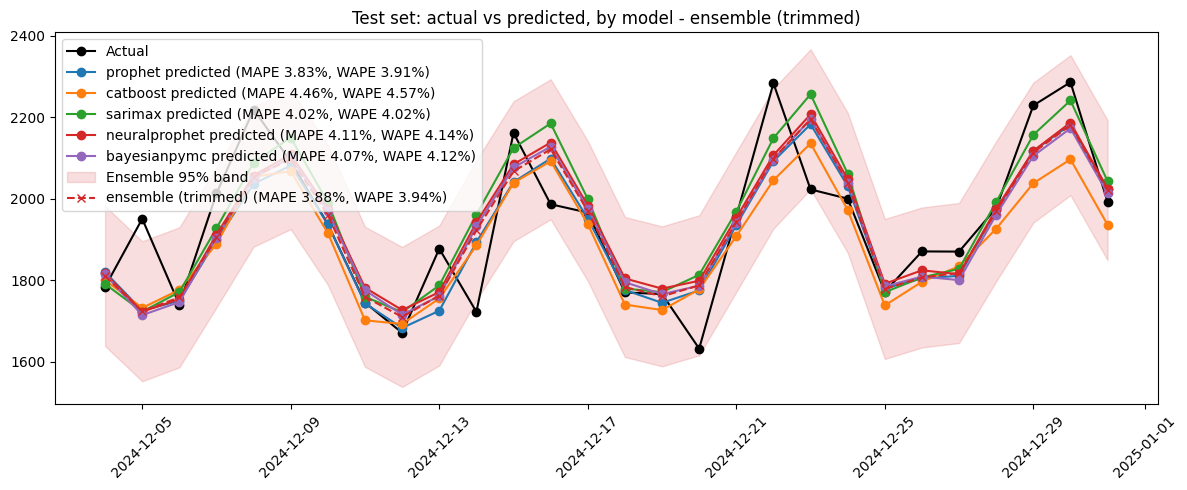

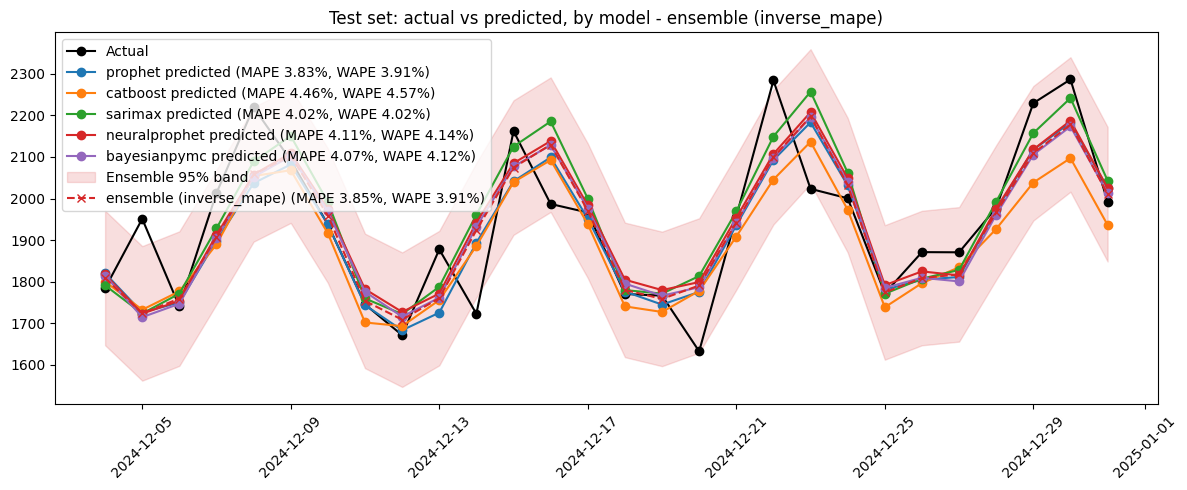

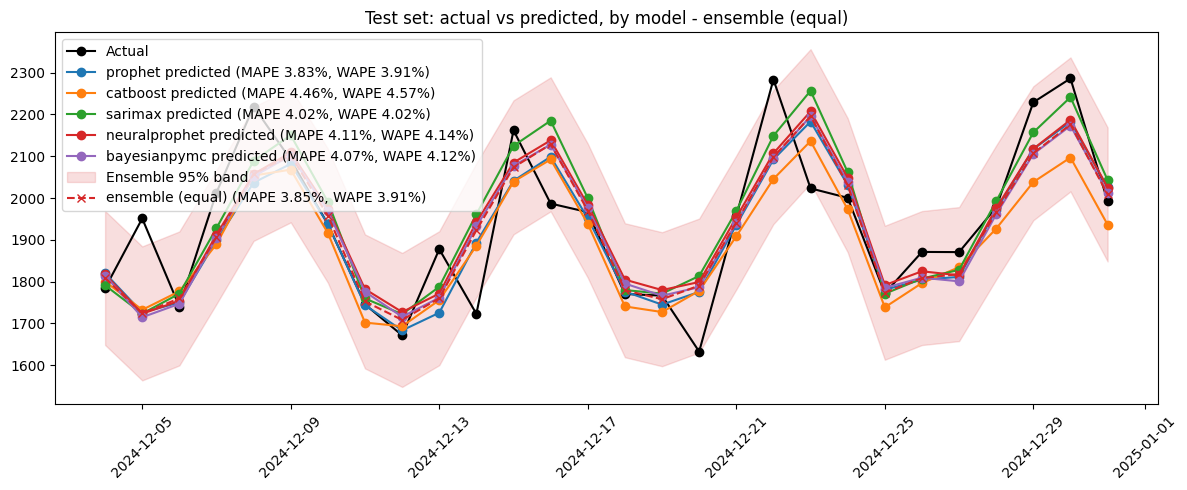

In [14]:
axes = plot_evaluation(results, forecaster.evaluate_ensemble)
print('charts returned:', list(axes))
plt.show()

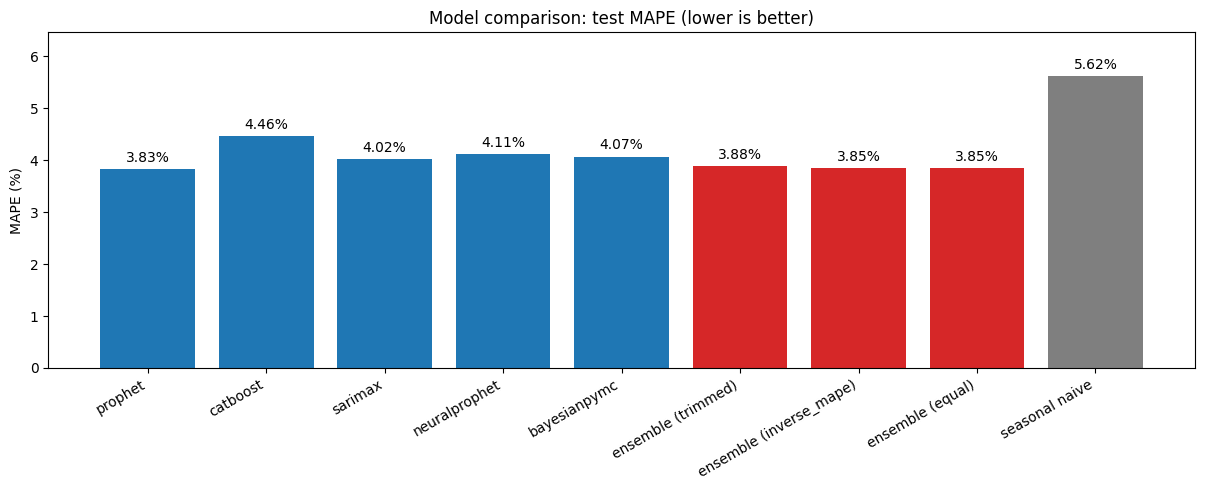

In [15]:
# Every rule on one axes -- comparing rules head to head is what a bar chart is for.
# These bars are TEST-window scores, on the metric the run selected with, not the validation
# scores the models were selected on. The grey bar is the seasonal-naive baseline.
plot_model_comparison(results, forecaster.evaluate_ensemble,
                      metric=forecaster.selection_metric, baseline=forecaster.naive_baseline)
plt.show()

figures: ['prophet', 'catboost', 'sarimax', 'neuralprophet', 'bayesianpymc', 'ensemble_trimmed', 'ensemble_inverse_mape', 'ensemble_equal']


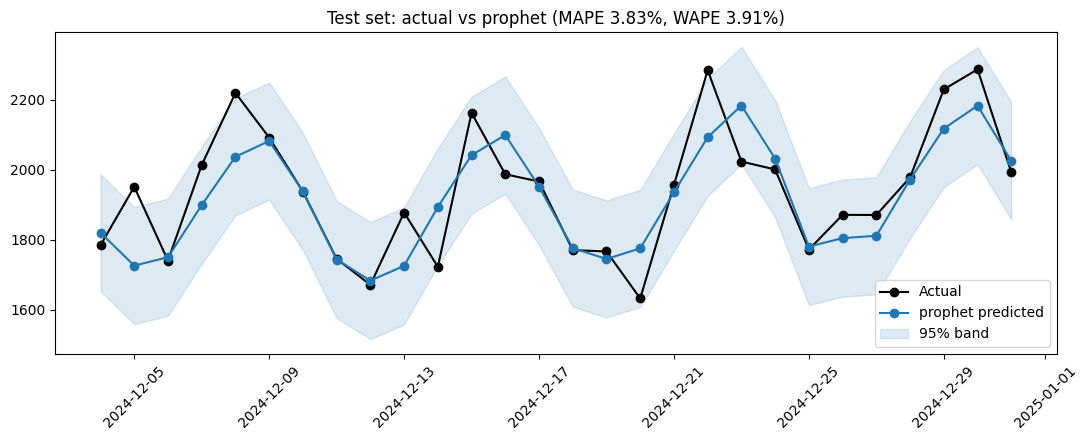

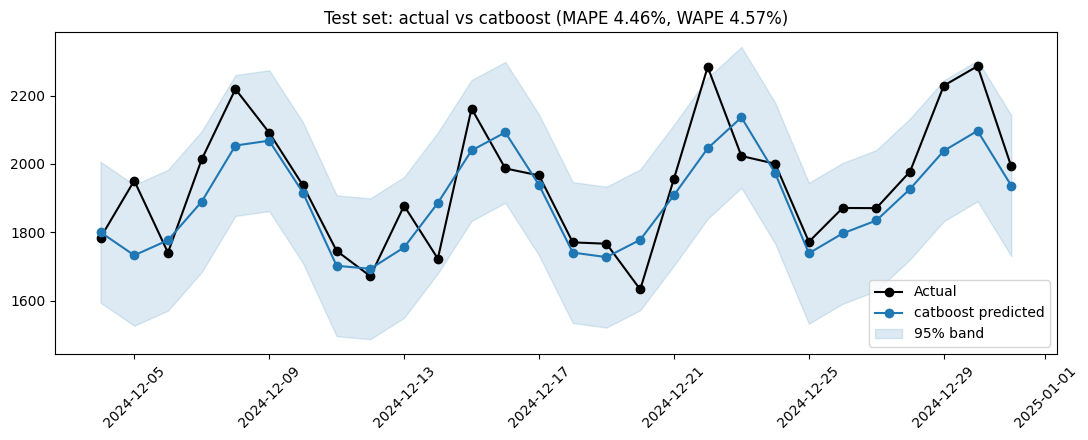

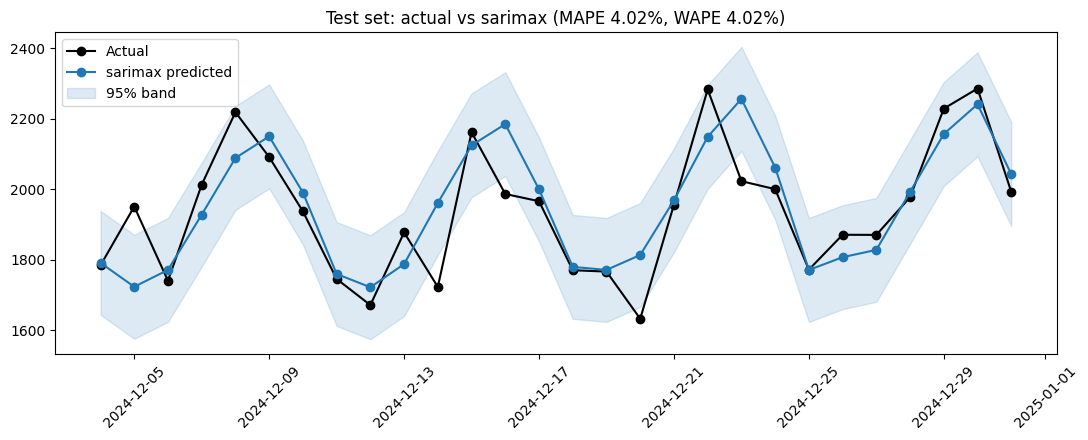

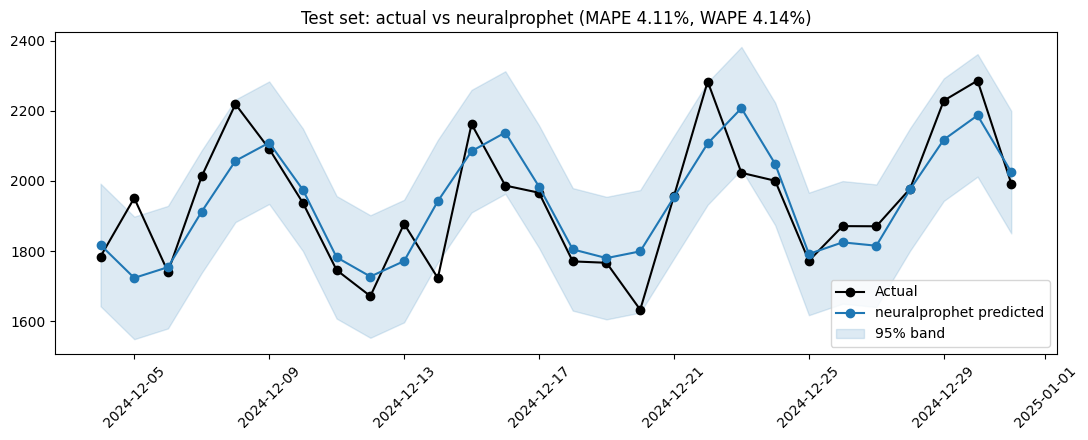

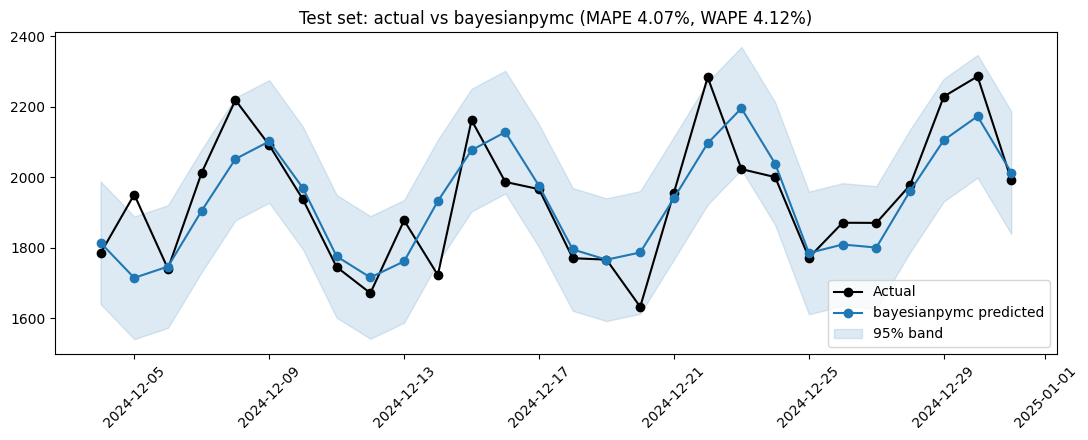

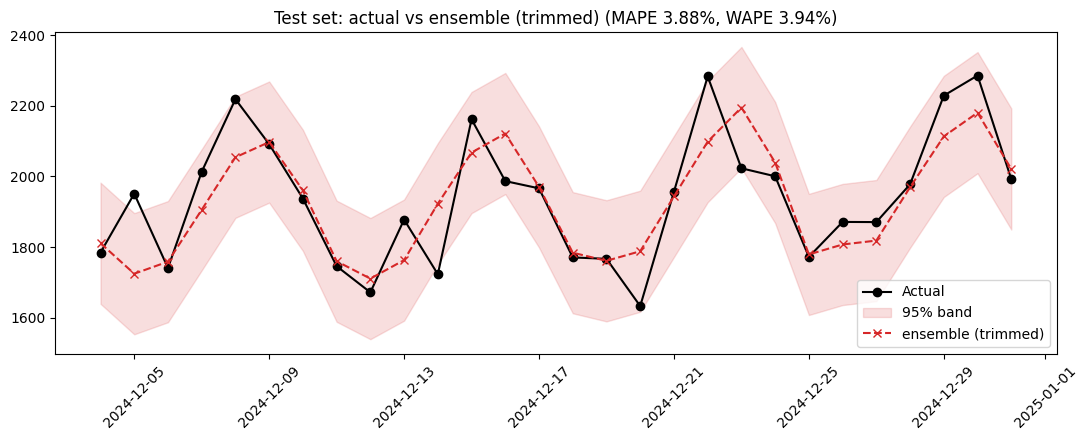

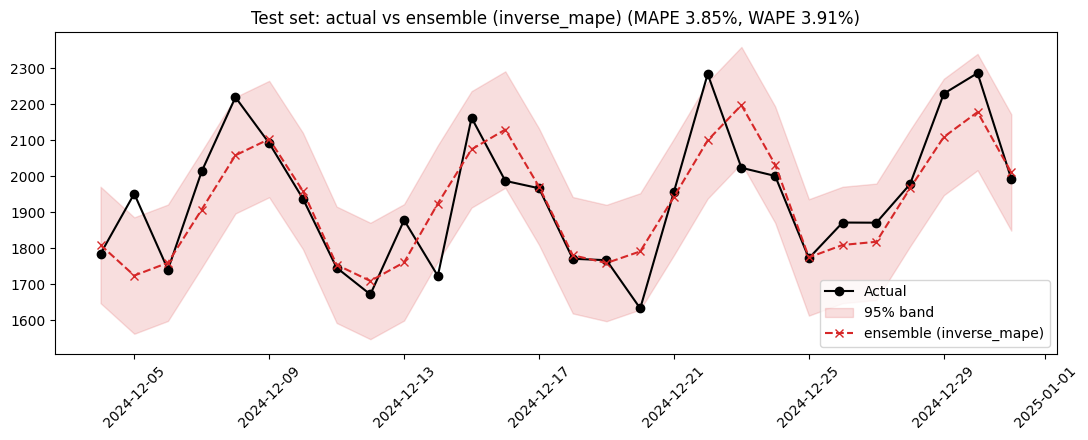

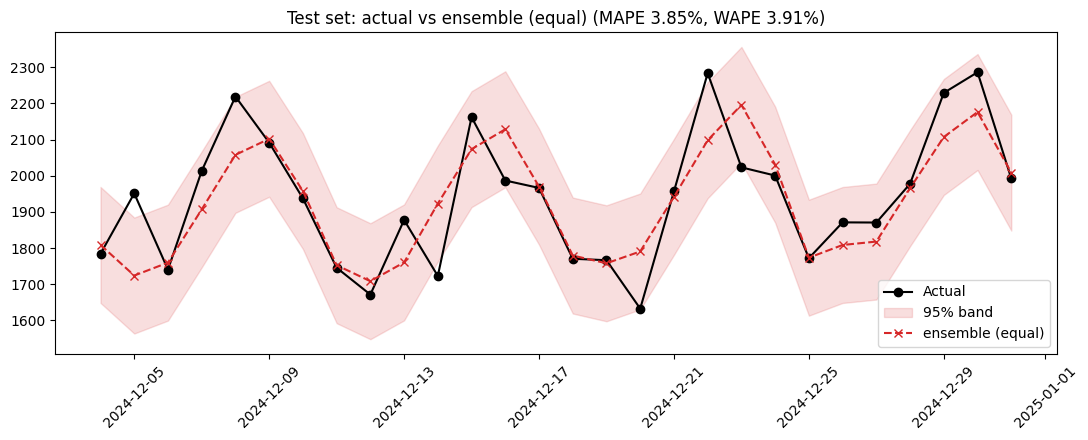

In [16]:
# One full-size figure per model, plus one per rule that formed. Easier to read than
# the overlay once several models agree and their lines sit on top of each other.
figures = plot_evaluation_per_model(results, forecaster.evaluate_ensemble)
print('figures:', list(figures))
plt.show()

## 5. Forecasting forward

This is where the driver columns earn their place, and where the distinction between drivers you know
and drivers you do not becomes concrete.

- `is_weekend` and `is_holiday` are **calendar facts**. We can compute them for any future date, so we supply them.
- `ad_spend` is **not knowable**. We leave it out, and the library generates it with the configured
  `carry_forward` strategy — and warns, loudly, that it has done so.

Supplying some columns and leaving others out is **partial fill**: a supplied column is used as-is and
only the missing ones are generated. The table also carries a `date` column, which the library checks against
the forecast dates, so a table that starts on the wrong day or skips one is refused rather than misapplied.
Partial fill matches the real case — you know next month's promotional
calendar, but not what spend will actually land.

In [17]:
HORIZON = 30

future_dates = pd.date_range(
    start=df['date'].max() + pd.Timedelta(days=1), periods=HORIZON, freq='D'
)

# Known-in-advance calendar flags. This dataset flags the same calendar days every year
# (1 Jan, 4 Jul, 28 Nov, 25 Dec), so the holidays in the forecast window are those days --
# here, New Year's Day. In a real run, mark your own holiday calendar: a holiday left at 0
# is a holiday the forecast does not know about.
holiday_days = set(df.loc[df['is_holiday'] == 1, 'date'].dt.strftime('%m-%d'))
future_drivers = pd.DataFrame({
    'date': future_dates,   # optional, but checked against the forecast dates when present
    'is_weekend': (future_dates.dayofweek >= 5).astype(int),
    'is_holiday': future_dates.strftime('%m-%d').isin(holiday_days).astype(int),
})
print('holidays in the forecast window:', list(future_dates[future_drivers['is_holiday'] == 1].strftime('%Y-%m-%d')))

print(f"supplying {list(future_drivers.columns.drop('date'))} for {HORIZON} periods; ad_spend will be generated")
future_drivers.head()

holidays in the forecast window: ['2025-01-01']
supplying ['is_weekend', 'is_holiday'] for 30 periods; ad_spend will be generated


,date,is_weekend,is_holiday
0,2025-01-01,0,1
1,2025-01-02,0,0
2,2025-01-03,0,0
3,2025-01-04,1,0
4,2025-01-05,1,0


In [18]:
%%time
forecasts = forecaster.forecast(horizon=HORIZON, future_independent_data=future_drivers)
print('failed to forecast:', dict(forecaster.forecast_errors) or 'none')

<timed exec>:1: UserWarning: future values for ['ad_spend'] were auto-generated for all 30 periods via the 'carry_forward' strategy (no values were supplied for them). The forecast is only as reliable as those assumed inputs -- for an exogenous-variable-driven model this can dominate the result. Supply real planned values if you have them (you can supply just some columns; the rest are filled), inspect what was assumed via forecaster.future_exog_used, and treat this output as a scenario rather than a prediction. The 95% bands assume these values are right: in testing, band coverage fell by about 9 points when drivers were generated rather than known.


failed to forecast: none
CPU times: user 5min 51s, sys: 669 ms, total: 5min 51s
Wall time: 5min 53s


Note the warning above: it names the columns that were invented and the strategy used, and says to
treat the output as a scenario rather than a prediction. That is deliberate — an exogenous-driven
forecast can be dominated by assumed inputs, and silently inventing them would hide that.

You can always inspect exactly what was assumed:

In [19]:
# Supplied columns and generated columns together, with the dates they apply to.
forecaster.future_exog_used.head()

,ds,ad_spend,is_weekend,is_holiday
0,2025-01-01,247.578503,0.0,1.0
1,2025-01-02,247.578503,0.0,0.0
2,2025-01-03,247.578503,0.0,0.0
3,2025-01-04,247.578503,1.0,0.0
4,2025-01-05,247.578503,1.0,0.0


Every forecast carries its band too. The horizon here, 30 days, is inside the 84
days of validation errors, so the band keeps its evaluated width throughout. Past 84
days it widens with the square root of the distance ahead, and `forecast()` warns that the far
end is a rough range rather than a 95% guarantee. The band also assumes the driver values are right:
the generated-drivers warning above says so.

In [20]:
# The default trimmed combination, with its band.
forecaster.forecast_ensemble['trimmed'].combined.head()

,ds,yhat,yhat_lower,yhat_upper
0,2025-01-01,1758.614947,1586.871257,1930.358638
1,2025-01-02,1795.049453,1623.305763,1966.793143
2,2025-01-03,1830.092291,1658.348601,2001.835981
3,2025-01-04,1999.422549,1827.678859,2171.166240
4,2025-01-05,2152.242082,1980.498392,2323.985773


charts returned: ['trimmed', 'inverse_mape', 'equal']


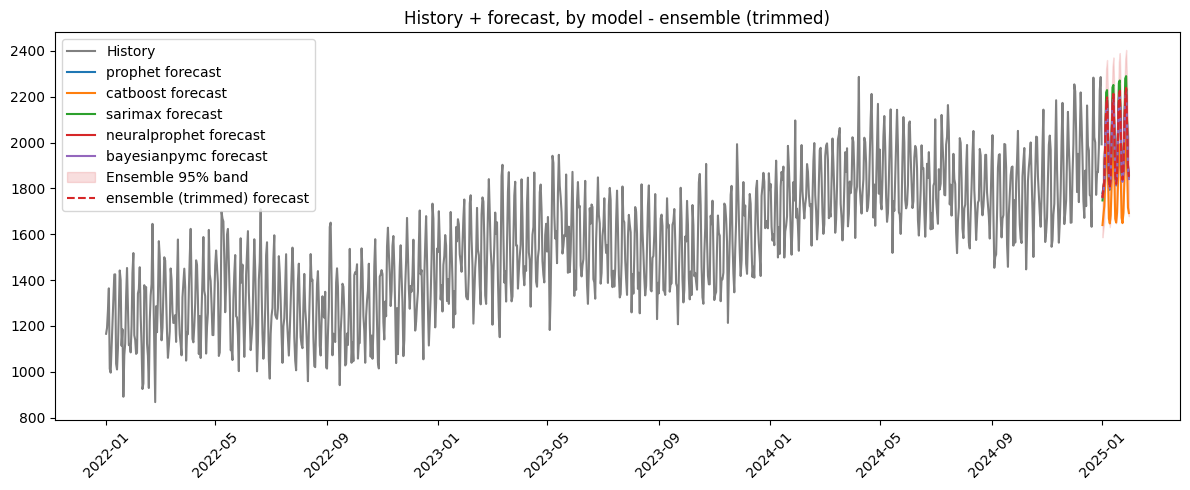

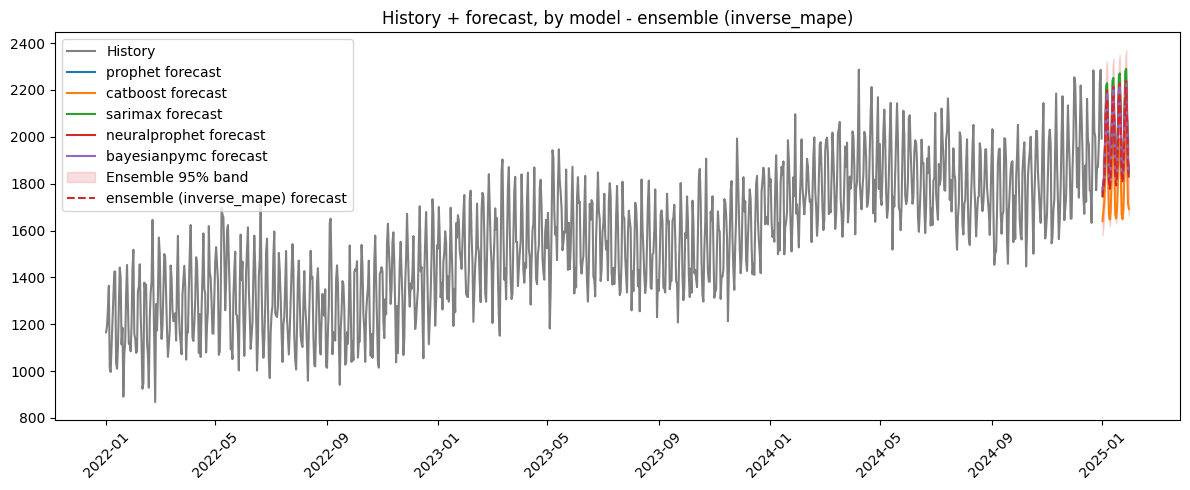

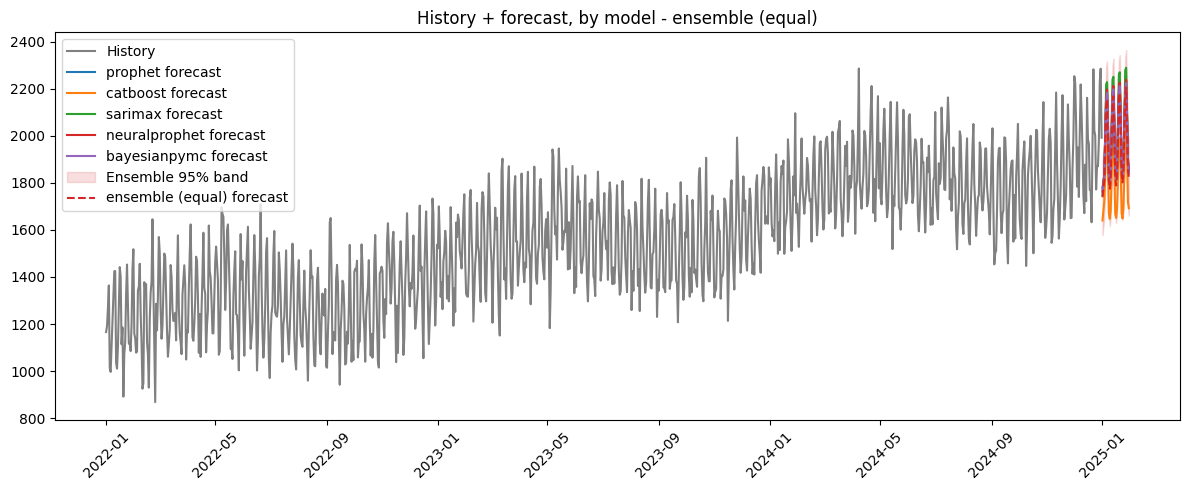

In [21]:
forecast_axes = plot_forecast(
    forecasts,
    history=df,
    date_column='date',
    target_column=TARGET,
    ensemble=forecaster.forecast_ensemble,
)
print('charts returned:', list(forecast_axes))
plt.show()

figures: ['prophet', 'catboost', 'sarimax', 'neuralprophet', 'bayesianpymc', 'ensemble_trimmed', 'ensemble_inverse_mape', 'ensemble_equal']


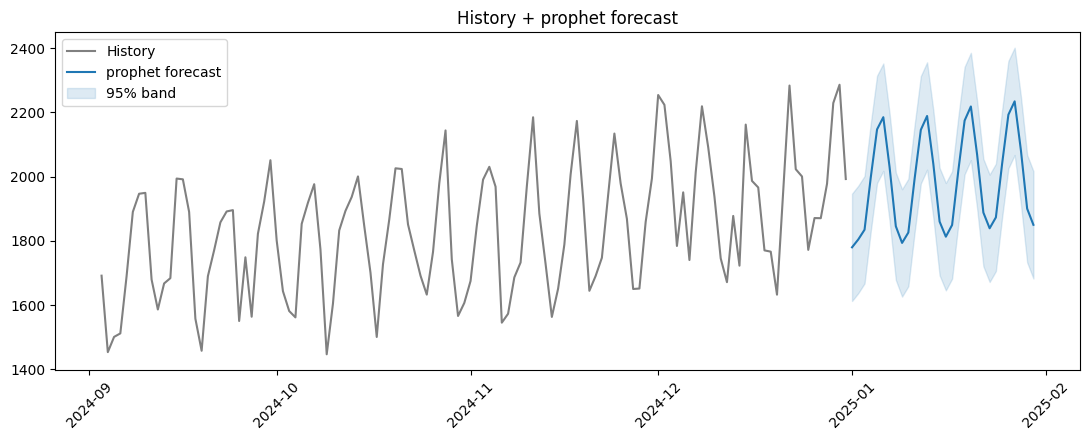

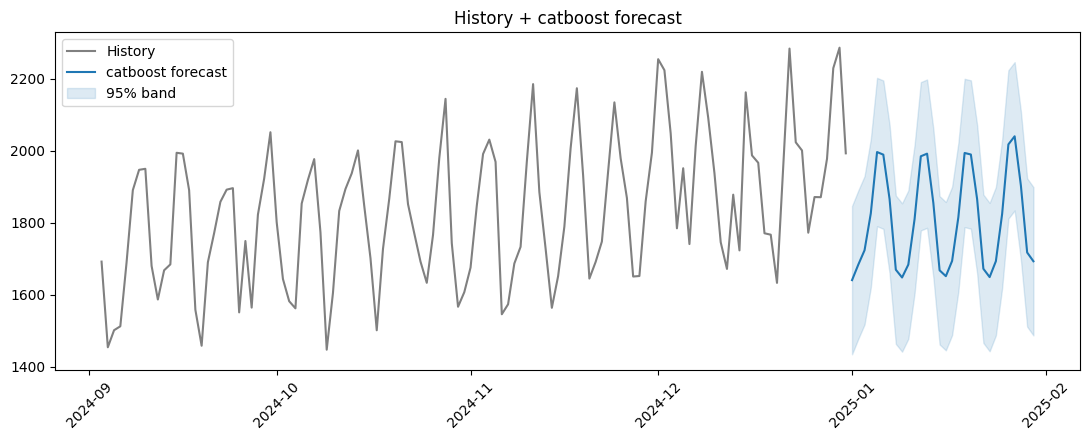

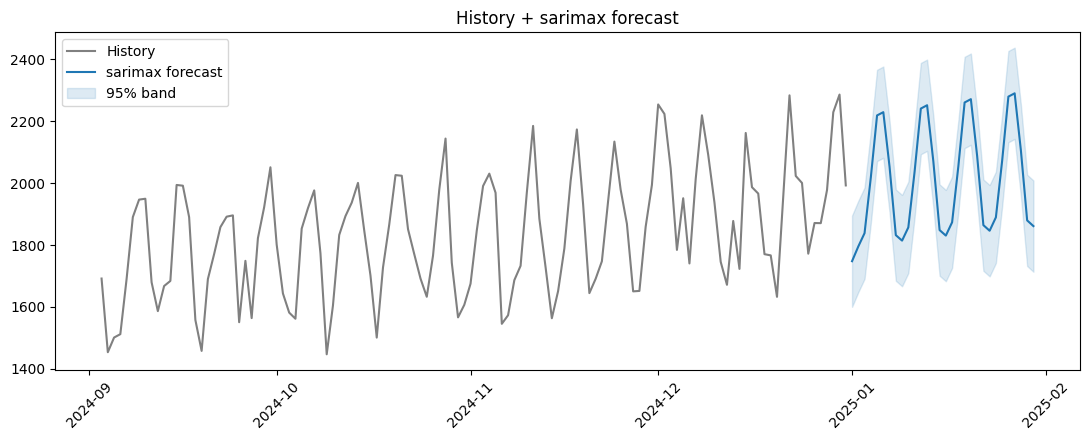

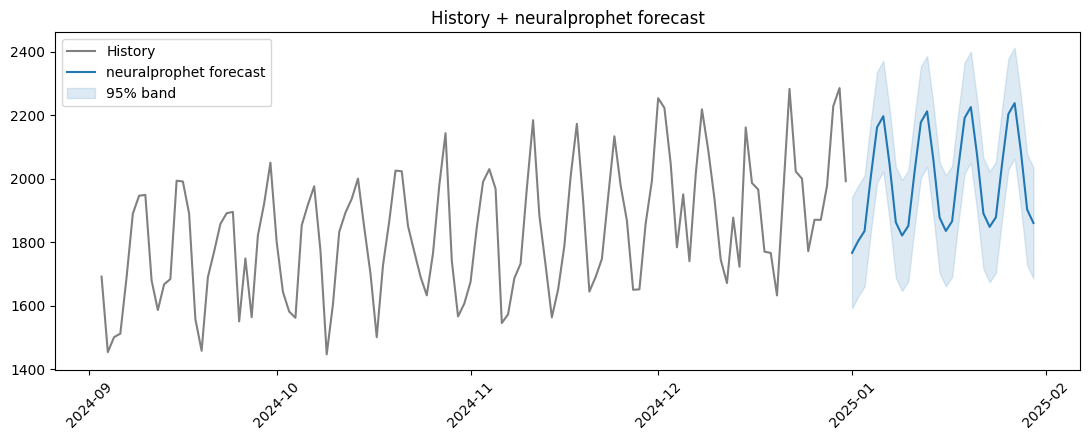

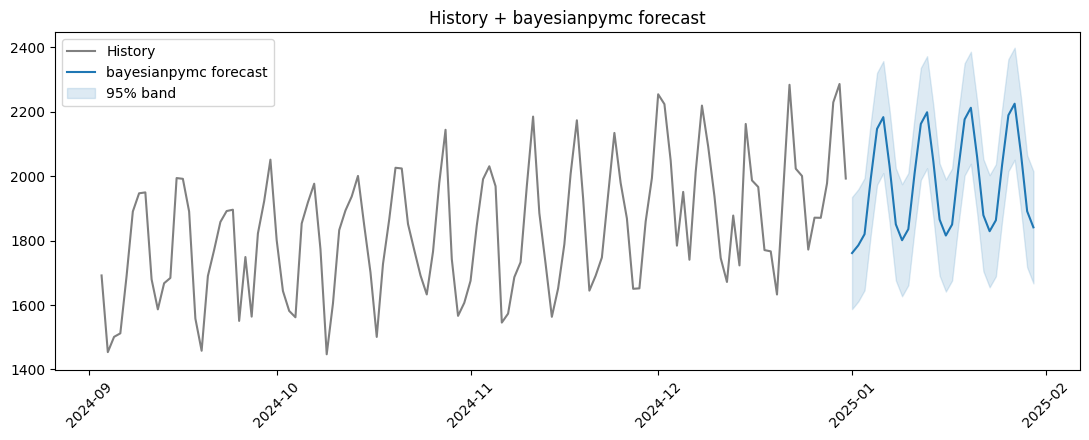

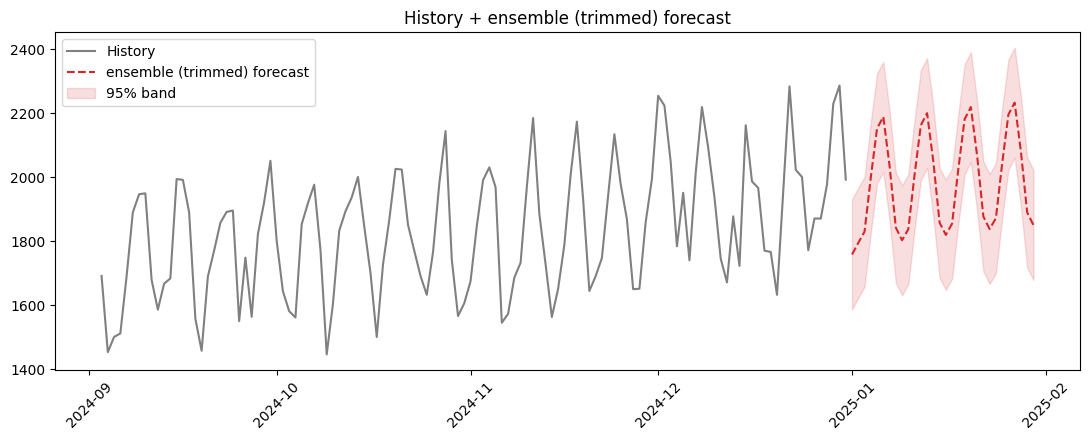

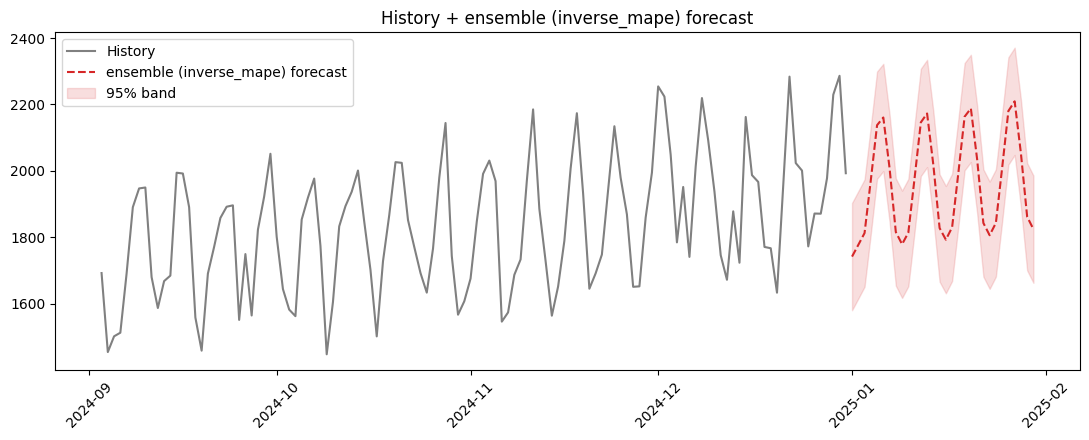

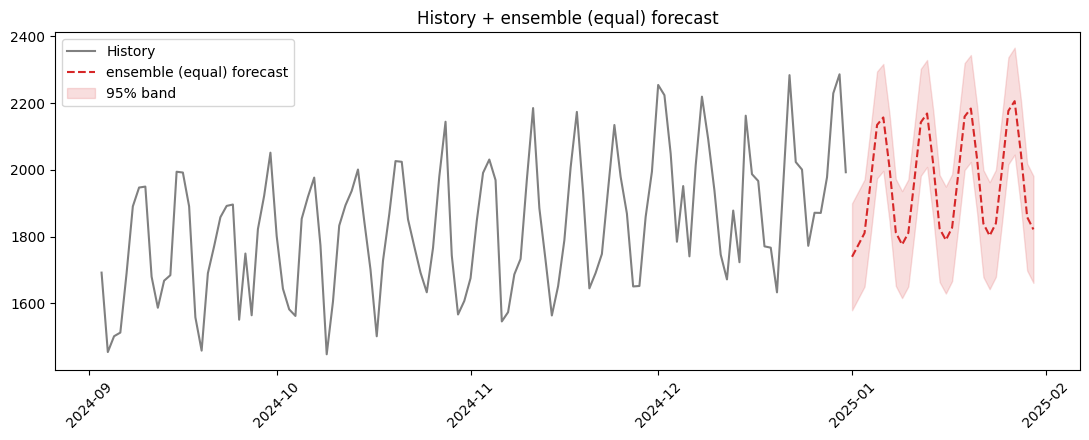

In [22]:
# One full-size figure per model's forecast, plus one per rule, each with its 95% band.
# Only the last 120 days of history are drawn, so the forecast and its band are readable.
forecast_figures = plot_forecast_per_model(
    forecasts,
    history=df.tail(120),
    date_column='date',
    target_column=TARGET,
    ensemble=forecaster.forecast_ensemble,
)
print('figures:', list(forecast_figures))
plt.show()

The forecast ensembles carry no MAPE of their own — there are no future actuals to score against.
Their screening and weighting reuse the **validation** score from hyperparameter selection, which
`forecast()` has to perform anyway in order to know which parameters to fit with.

## 6. Export

One call writes the CSVs and the charts into a single folder.

In [23]:
paths = export_forecast(
    forecasts,
    forecaster=forecaster,     # fills in the ensembles, every score, the threshold and the baseline
    history=df,
    date_column='date',
    target_column=TARGET,
    output_dir='output',
    prefix='daily',
    save_plots=True,
)

for key in sorted(paths):
    print(f'{key:34s} {paths[key]}')

error_correlation                  output/daily_error_correlation.csv
final_best_model                   output/daily_final_best_model.csv
final_ensemble_equal               output/daily_final_ensemble_equal.csv
final_ensemble_inverse_mape        output/daily_final_ensemble_inverse_mape.csv
final_ensemble_trimmed             output/daily_final_ensemble_trimmed.csv
model_summary                      output/daily_model_summary.csv
per_model                          output/daily_per_model.csv
plot_bayesianpymc                  output/daily_bayesianpymc.png
plot_catboost                      output/daily_catboost.png
plot_ensemble_equal                output/daily_ensemble_equal.png
plot_ensemble_inverse_mape         output/daily_ensemble_inverse_mape.png
plot_ensemble_trimmed              output/daily_ensemble_trimmed.png
plot_neuralprophet                 output/daily_neuralprophet.png
plot_overlay_equal                 output/daily_overlay_equal.png
plot_overlay_inverse_mape          ou

`final_ensemble_<method>` is written once per combination rule, and `final_best_model` alongside it.
The export deliberately does not choose between them — `model_summary.csv` carries the validation and
test MAPE and WAPE side by side, whether each model and rule beats the seasonal-naive baseline (which
has a row of its own), and why each model was or was not exported as the best, so you can make that
call per run, with the evidence in hand. `error_correlation.csv` shows how alike the models' mistakes are.

Every forecast CSV carries the 95% band in `yhat_lower` / `yhat_upper`, and `model_summary` reports `band_coverage` and `band_test_points`: the share of the test window's actuals each band held, and over how many points.

In [24]:
pd.read_csv(paths['model_summary'])

,model,validation_mape,mape,ensemble_method,rule_applied,ensemble_weight,status,best_model_check,validation_wape,wape,zero_actuals_excluded,beats_naive,selection_metric,band_coverage,band_test_points
0,prophet,3.654321,3.827557,trimmed,trimmed,NaN,in_ensemble,passed,3.574387,3.909751,0,True,mape,85.714286,28.0
1,catboost,4.074699,4.458392,trimmed,trimmed,NaN,in_ensemble,passed,4.143473,4.572821,0,True,mape,92.857143,28.0
2,sarimax,3.642050,4.021598,trimmed,trimmed,NaN,in_ensemble,passed,3.544082,4.017501,0,True,mape,82.142857,28.0
3,neuralprophet,3.629990,4.113388,trimmed,trimmed,NaN,in_ensemble,passed,3.551282,4.140450,0,True,mape,85.714286,28.0
4,bayesianpymc,3.596167,4.068855,trimmed,trimmed,NaN,in_ensemble,exported as best: lowest validation MAPE among...,3.509642,4.121772,0,True,mape,89.285714,28.0
5,ensemble,NaN,3.882280,trimmed,trimmed,1.000000,ensemble,NaN,NaN,3.938846,0,True,mape,85.714286,28.0
6,prophet,3.654321,3.827557,inverse_mape,inverse_mape,0.203125,in_ensemble,passed,3.574387,3.909751,0,True,mape,85.714286,28.0
7,catboost,4.074699,4.458392,inverse_mape,inverse_mape,0.182169,in_ensemble,passed,4.143473,4.572821,0,True,mape,92.857143,28.0
8,sarimax,3.642050,4.021598,inverse_mape,inverse_mape,0.203809,in_ensemble,passed,3.544082,4.017501,0,True,mape,82.142857,28.0
9,neuralprophet,3.629990,4.113388,inverse_mape,inverse_mape,0.204487,in_ensemble,passed,3.551282,4.140450,0,True,mape,85.714286,28.0


## Where to go next

- [`docs/quickstart.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/quickstart.md) — the full API walkthrough
- [`docs/supported_models.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/supported_models.md) — what each model does, its caveats, and how the 95% bands are built
- [`docs/ensemble_methods.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/ensemble_methods.md) — the combination rules in detail
- [`docs/future_exog.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/future_exog.md) — the other future-driver strategies
- [`docs/design_notes.md`](https://github.com/Lifesight-Software-Pvt-Ltd/horizon/blob/main/docs/design_notes.md) — why the library is built this way

**An honest caveat about this example.**

The data is simulated, with an only continuous driver that carries little signal, so treat the numbers as a demonstration
that the machinery works, not as evidence about how well these models forecast your series.